---
title: "3.6.d Escenarios: aguaceros más intensos"
short_title: "d. Escenarios"
subtitle: "Proyecciones CMIP6 de lluvia extrema y viento"
description: "Escenarios de cambio climático para la lluvia extrema y el viento en Leticia."
keywords: [lluvia extrema, CMIP6, Clausius-Clapeyron, escenarios, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/36_lluvias_vendavales/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

Una atmósfera más cálida contiene más vapor de agua: ~7 % más por cada grado de calentamiento (relación de
Clausius-Clapeyron). Por eso, aunque la lluvia anual cambie poco, los aguaceros más intensos tienden a crecer
[@castellanos2022ipcc].

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, viz

VARS = {"rx1day": "lluvia máxima en 1 día (mm)", "rx5day": "lluvia máxima en 5 días (mm)", "pr": "lluvia anual (mm)"}
tabla = fuentes.cckp_tabla(list(VARS))
base = fuentes.cckp_historico(list(VARS))

**Cambio porcentual de la mediana del ensamble respecto a 1995–2014:**

2040-2059                   2080-2099                  
                              SSP1-2.6 SSP2-4.5 SSP5-8.5  SSP1-2.6 SSP2-4.5 SSP5-8.5
lluvia máxima en 1 día (mm)       5.80     7.40     9.90      7.80     9.70    21.20
lluvia máxima en 5 días (mm)      4.50     5.20     4.70      4.80     8.90     9.70
lluvia anual (mm)                -2.40    -2.40    -3.60     -1.40    -3.50    -8.90

**Días con lluvia ≥ 20 mm:** 14 por año en 1995–2014; cambio proyectado (días/año, mediana):

escenario,SSP1-2.6,SSP2-4.5,SSP5-8.5
periodo,,,
2040-2059,1.00,1.30,1.40
2080-2099,1.50,2.50,3.20


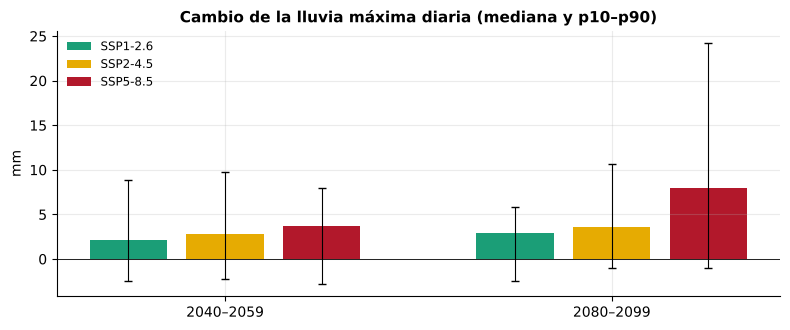

In [3]:
med = tabla.pivot_table(index="variable", columns=["periodo", "escenario", "percentil"], values="valor")
rel = pd.DataFrame({(per, viz.NOMBRE_ESC[esc]): 100 * tabla[(tabla.periodo == per) & (tabla.escenario == esc) & (tabla.percentil == "median")]
                    .set_index("variable")["valor"] / base for per in ("2040-2059", "2080-2099") for esc in ("ssp126", "ssp245", "ssp585")})
rel.index = [VARS[v] for v in rel.index]
display(Markdown("**Cambio porcentual de la mediana del ensamble respecto a 1995–2014:**"))
display(rel.round(1))
r20 = fuentes.cckp_tabla(["r20mm"])
b20 = float(fuentes.cckp_historico(["r20mm"]).iloc[0])
t20 = r20[r20.percentil == "median"].pivot_table(index="periodo", columns="escenario", values="valor").rename(columns=viz.NOMBRE_ESC)
display(Markdown(f"**Días con lluvia ≥ 20 mm:** {b20:.0f} por año en 1995–2014; cambio proyectado (días/año, mediana):"))
display(t20.round(1))
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, esc in enumerate(("ssp126", "ssp245", "ssp585")):
    sub = tabla[(tabla.variable == "rx1day") & (tabla.escenario == esc)]
    for k, per in enumerate(("2040-2059", "2080-2099")):
        d = sub[sub.periodo == per].set_index("percentil")["valor"]
        x = k * 4 + j
        ax.bar(x, d["median"], color=viz.ESCENARIOS[esc], label=viz.NOMBRE_ESC[esc] if k == 0 else None)
        ax.errorbar(x, d["median"], yerr=[[d["median"] - d["p10"]], [d["p90"] - d["median"]]], color="k", capsize=3, lw=0.8)
ax.set_xticks([1, 5]); ax.set_xticklabels(["2040–2059", "2080–2099"])
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("mm")
ax.set_title("Cambio de la lluvia máxima diaria (mediana y p10–p90)")
ax.legend()
fig.tight_layout()

In [4]:
viz.pie(viz.nota_fuente("proyecciones_cckp"))

*Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5.*

**Lectura.** El ensamble proyecta un aumento moderado de la lluvia máxima diaria y de 5 días, mayor con más
emisiones, con una dispersión amplia entre modelos. Para el diseño de drenajes urbanos conviene adoptar un
**factor de seguridad climático** (por ejemplo, +10 % a +20 % sobre las intensidades actuales) mientras se
actualizan las curvas IDF del IDEAM. Las proyecciones de viento extremo de los modelos globales son poco
confiables para tormentas convectivas; la gestión debe apoyarse en la vigilancia y la alerta temprana.